**作业采用的肺癌数据集的字段描述：**

- AGE: 患者的年龄。
- GENDER: 患者的性别 (1 表示男性, 0 表示女性)。
- SMOKING: 是否吸烟 (1 表示吸烟, 0 表示不吸烟)。
- FINGER_DISCOLORATION: 是否有指甲变色 (1 表示有, 0 表示没有)。
- MENTAL_STRESS: 是否有精神压力 (1 表示有, 0 表示没有)。
- EXPOSURE_TO_POLLUTION: 是否暴露于污染环境中 (1 表示有, 0 表示没有)。
- LONG_TERM_ILLNESS: 是否有长期疾病 (1 表示有, 0 表示没有)。
- ENERGY_LEVEL: 患者的能量水平（较低的值通常表示能量水平较低，较高的值表示能量较高）。
- IMMUNE_WEAKNESS: 免疫系统是否较弱 (1 表示是, 0 表示否)。
- BREATHING_ISSUE: 是否有呼吸问题 (1 表示有, 0 表示没有)。
- ALCOHOL_CONSUMPTION: 是否有饮酒习惯 (1 表示有, 0 表示没有)。
- THROAT_DISCOMFORT: 是否有喉咙不适 (1 表示有, 0 表示没有)。
- OXYGEN_SATURATION: 患者的血氧饱和度，表示血液中氧气的含量。
- CHEST_TIGHTNESS: 是否感到胸部紧张 (1 表示有, 0 表示没有)。
- FAMILY_HISTORY: 是否有家族历史 (1 表示有, 0 表示没有)。
- SMOKING_FAMILY_HISTORY: 是否有家族吸烟史 (1 表示有, 0 表示没有)。
- STRESS_IMMUNE: 是否经历过较高的压力，影响免疫系统 (1 表示是, 0 表示否)。
- PULMONARY_DISEASE: 是否患有肺部疾病 (YES 或 NO)，这是目标变量，可能用于分类预测肺癌风险。

该数据集记录了患者的健康和生活习惯信息，以及他们是否患有肺部疾病（最后一列 PULMONARY_DISEASE），可以用于建立模型来分析哪些因素（如吸烟、精神压力、呼吸问题等）可能与肺部疾病（如肺癌）的发生有关。

In [1]:
# 启用美观打印设置
import pandas as pd
pd.set_option('display.max_rows', 10)  # 控制显示的最大行数
pd.set_option('display.max_columns', None)  # 显示所有列
pd.set_option('display.width', None)  # 自动调整输出宽度
pd.set_option('display.max_colwidth', None)  # 让每一列的宽度自动调整
pd.set_option('display.max_rows', 20)  # 只显示前20行

## 1. 使用 Pandas 读取该 CSV 文件，并查看数据的基本信息（如列名、数据类型、缺失值等）。

**参考知识点：**
- 使用 `pandas.read_csv()` 读取 CSV 文件
- 使用 `.info()` 查看数据类型和缺失值
- 使用 `.head()` 查看数据的head = data.head()


In [2]:
data = pd.read_csv('lung_cancer_data.csv')
data.info()
print('前5行数据：')
print(data.head())
print()
print('每一列的缺失值数量：')
print(data.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   AGE                     5000 non-null   int64  
 1   GENDER                  5000 non-null   int64  
 2   SMOKING                 5000 non-null   int64  
 3   FINGER_DISCOLORATION    5000 non-null   int64  
 4   MENTAL_STRESS           5000 non-null   int64  
 5   EXPOSURE_TO_POLLUTION   5000 non-null   int64  
 6   LONG_TERM_ILLNESS       5000 non-null   int64  
 7   ENERGY_LEVEL            5000 non-null   float64
 8   IMMUNE_WEAKNESS         5000 non-null   int64  
 9   BREATHING_ISSUE         5000 non-null   int64  
 10  ALCOHOL_CONSUMPTION     5000 non-null   int64  
 11  THROAT_DISCOMFORT       5000 non-null   int64  
 12  OXYGEN_SATURATION       5000 non-null   float64
 13  CHEST_TIGHTNESS         5000 non-null   int64  
 14  FAMILY_HISTORY          5000 non-null   int64  
 15

In [3]:
import pandas as pd  # 导入pandas库

# 1. 查看每一列的缺失值数量
missing_values = data.isnull().sum()
print("每一列的缺失值数量：")
print(missing_values)

# 2. 处理缺失值（根据情况填充）
# 填充类别型数据的缺失值（使用众数填充）
data['SMOKING'] = data['SMOKING'].fillna(data['SMOKING'].mode()[0])  # 用众数填充SMOKING
data['ALCOHOL_CONSUMPTION'] = data['ALCOHOL_CONSUMPTION'].fillna(data['ALCOHOL_CONSUMPTION'].mode()[0])  # 用众数填充ALCOHOL_CONSUMPTION
data['CHEST_TIGHTNESS'] = data['CHEST_TIGHTNESS'].fillna(data['CHEST_TIGHTNESS'].mode()[0])  # 用众数填充CHEST_TIGHTNESS
data['FAMILY_HISTORY'] = data['FAMILY_HISTORY'].fillna(data['FAMILY_HISTORY'].mode()[0])  # 用众数填充FAMILY_HISTORY
data['SMOKING_FAMILY_HISTORY'] = data['SMOKING_FAMILY_HISTORY'].fillna(data['SMOKING_FAMILY_HISTORY'].mode()[0])  # 用众数填充SMOKING_FAMILY_HISTORY
data['LONG_TERM_ILLNESS'] = data['LONG_TERM_ILLNESS'].fillna(data['LONG_TERM_ILLNESS'].mode()[0])  # 用众数填充LONG_TERM_ILLNESS

# 填充数值型数据的缺失值（使用平均数填充）
data['ENERGY_LEVEL'] = data['ENERGY_LEVEL'].fillna(data['ENERGY_LEVEL'].mean())  # 用平均数填充ENERGY_LEVEL
data['OXYGEN_SATURATION'] = data['OXYGEN_SATURATION'].fillna(data['OXYGEN_SATURATION'].mean())  # 用平均数填充OXYGEN_SATURATION

# 3. 确认缺失值已处理
missing_values_after = data.isnull().sum()
print("\n处理缺失值后的数据缺失情况：")
print(missing_values_after)


每一列的缺失值数量：
AGE                       0
GENDER                    0
SMOKING                   0
FINGER_DISCOLORATION      0
MENTAL_STRESS             0
EXPOSURE_TO_POLLUTION     0
LONG_TERM_ILLNESS         0
ENERGY_LEVEL              0
IMMUNE_WEAKNESS           0
BREATHING_ISSUE           0
ALCOHOL_CONSUMPTION       0
THROAT_DISCOMFORT         0
OXYGEN_SATURATION         0
CHEST_TIGHTNESS           0
FAMILY_HISTORY            0
SMOKING_FAMILY_HISTORY    0
STRESS_IMMUNE             0
PULMONARY_DISEASE         0
dtype: int64

处理缺失值后的数据缺失情况：
AGE                       0
GENDER                    0
SMOKING                   0
FINGER_DISCOLORATION      0
MENTAL_STRESS             0
EXPOSURE_TO_POLLUTION     0
LONG_TERM_ILLNESS         0
ENERGY_LEVEL              0
IMMUNE_WEAKNESS           0
BREATHING_ISSUE           0
ALCOHOL_CONSUMPTION       0
THROAT_DISCOMFORT         0
OXYGEN_SATURATION         0
CHEST_TIGHTNESS           0
FAMILY_HISTORY            0
SMOKING_FAMILY_HISTORY    0
STRESS_I

## 2. 考虑上面的例子和代码，回答下列问题：
- 如果我们不采用填充缺失值来处理，而是仅仅删除掉含有缺失值的行，怎么做？在下方的文本框中用一行代码回答（不运行）
- 在下方的文本框中谈谈相比于直接删除掉包含缺失值的行，使用数据进行填充的好处（***少于50字，多了不给分，分要点列出***）

**删除含有缺失值的行：**

```python
data = data.dropna()
```

**填充的好处：**
- 保留全部样本，不浪费数据
- 避免删行造成信息丢失和结果偏差

## 3. 计算数据集中所有患者的平均年龄，并根据年龄区间（如 '20-35', '35-50', '50-65', '65-80', '80+'）对数据进行分组。

**参考知识点：**
- 使用 `mean()` 计算平均年龄
- 使用 `pd.cut()` 进行年龄区间分组


In [4]:
avg_age = data['AGE'].mean()
print('所有患者的平均年龄：', round(avg_age, 2))

age_bins = [20, 35, 50, 65, 80, 100]
age_labels = ['20-35', '35-50', '50-65', '65-80', '80+']
data['AGE_GROUP'] = pd.cut(data['AGE'], bins=age_bins, labels=age_labels, right=False)

print()
print('各年龄组患者数量：')
print(data['AGE_GROUP'].value_counts().sort_index())

所有患者的平均年龄： 57.22

各年龄组患者数量：
AGE_GROUP
20-35     450
35-50    1301
50-65    1428
65-80    1357
80+       464
Name: count, dtype: int64


## 4. 首先，在下面第一个代码框中，根据吸烟状态（SMOKING 列），统计吸烟和不吸烟的患者数量，并绘制柱状图表示这两类患者的数量；其次，在下面第二个代码框中，利用先前得到的年龄分组'AGE_GROUP'列和groupby函数，绘制每个年龄组内的吸烟与不吸烟患者数量的柱状图。

**参考知识点：**
- 使用 `value_counts()` 统计吸烟和不吸烟患者数量
- 使用 `matplotlib.pyplot` 绘者数量')
plt.show()


吸烟状态人数统计：
SMOKING
0    1668
1    3332
Name: count, dtype: int64


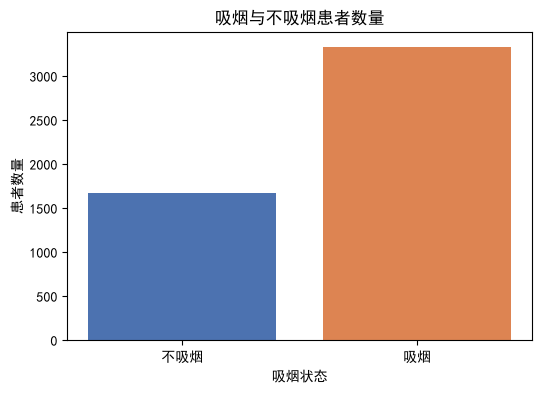

In [5]:
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'Heiti TC']
plt.rcParams['axes.unicode_minus'] = False

smoking_counts = data['SMOKING'].value_counts().sort_index()
print('吸烟状态人数统计：')
print(smoking_counts)

plt.figure(figsize=(6, 4))
plt.bar(['不吸烟', '吸烟'], smoking_counts.values, color=['#4C72B0', '#DD8452'])
plt.title('吸烟与不吸烟患者数量')
plt.xlabel('吸烟状态')
plt.ylabel('患者数量')
plt.show()

各年龄组吸烟与不吸烟患者数量：
           不吸烟   吸烟
AGE_GROUP          
20-35      134  316
35-50      415  886
50-65      487  941
65-80      462  895
80+        170  294


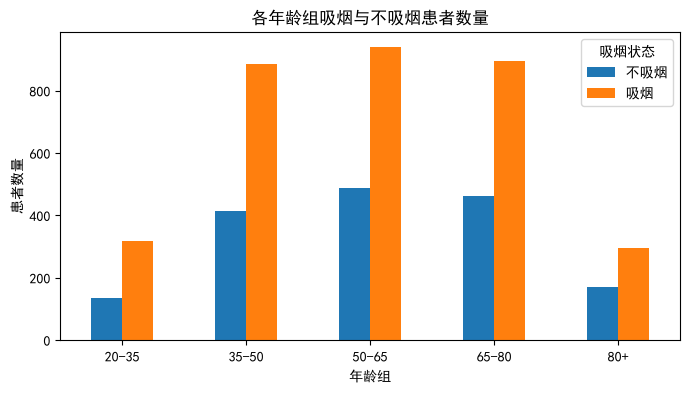

In [6]:
age_smoking_table = (data.groupby(['AGE_GROUP', 'SMOKING'], observed=False)
                     .size()
                     .unstack(fill_value=0)
                     .reindex(columns=[0, 1], fill_value=0))
age_smoking_table.columns = ['不吸烟', '吸烟']

print('各年龄组吸烟与不吸烟患者数量：')
print(age_smoking_table)

age_smoking_table.plot(kind='bar', figsize=(8, 4))
plt.title('各年龄组吸烟与不吸烟患者数量')
plt.xlabel('年龄组')
plt.ylabel('患者数量')
plt.xticks(rotation=0)
plt.legend(title='吸烟状态')
plt.show()

## 5. 根据是否有呼吸问题（BREATHING_ISSUE 列）分组并计算不同组的平均能量水平（ENERGY_LEVEL 列）。

**参考知识点：**
- 使用 `groupby()` 方法按列分组
- 使用 `.mean()` 计算平均值``'].mean()


In [7]:
breathing_energy_mean = data.groupby('BREATHING_ISSUE')['ENERGY_LEVEL'].mean()
print('不同呼吸问题分组下的平均能量水平：')
print(breathing_energy_mean)

不同呼吸问题分组下的平均能量水平：
BREATHING_ISSUE
0    55.046377
1    55.028469
Name: ENERGY_LEVEL, dtype: float64


## 6. 筛选出年龄大于 60 岁并且有肺部疾病（PULMONARY_DISEASE 列为 YES）的患者，显示这些患者的详细信息。

**参考知识点：**
- 对数据进行条件筛选


In [8]:
senior_disease_patients = data[(data['AGE'] > 60) & (data['PULMONARY_DISEASE'] == 'YES')]
print('符合条件的患者数量：', len(senior_disease_patients))
senior_disease_patients

符合条件的患者数量： 890


,AGE,GENDER,SMOKING,FINGER_DISCOLORATION,MENTAL_STRESS,EXPOSURE_TO_POLLUTION,LONG_TERM_ILLNESS,ENERGY_LEVEL,IMMUNE_WEAKNESS,BREATHING_ISSUE,ALCOHOL_CONSUMPTION,THROAT_DISCOMFORT,OXYGEN_SATURATION,CHEST_TIGHTNESS,FAMILY_HISTORY,SMOKING_FAMILY_HISTORY,STRESS_IMMUNE,PULMONARY_DISEASE,AGE_GROUP
1,81,1,1,0,0,1,1,47.694835,1,1,0,1,97.184483,0,0,0,0,YES,80+
4,72,0,1,1,1,1,1,59.733941,0,1,0,1,93.503008,0,0,0,0,YES,65-80
14,65,1,1,0,1,0,0,49.976264,1,1,0,1,95.440149,0,0,0,1,YES,65-80
27,62,1,1,0,0,0,0,61.951067,1,1,0,1,94.949919,0,1,1,0,YES,50-65
32,78,0,1,0,1,1,0,60.858788,1,1,0,0,91.924279,0,0,0,1,YES,65-80
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4983,82,1,1,1,1,1,1,51.911484,0,1,1,1,97.534566,0,0,0,0,YES,80+
4984,70,1,1,0,1,0,1,49.228224,1,1,1,1,94.297105,1,0,0,1,YES,65-80
4987,66,1,1,0,0,1,1,49.170383,1,1,0,1,93.762354,1,1,1,0,YES,65-80
4992,67,0,1,1,1,0,0,63.145396,0,1,0,1,96.557856,0,0,0,0,YES,65-80


## 7. 使用 Pandas 创建一个数据透视表，显示不同性别（GENDER 列）和精神压力（MENTAL_STRESS 列）组合下，是否有肺部疾病的情况。

**参考知识点：**
- 使用 `pd.pivot_table()` 创建数据透视表


In [9]:
gender_stress_pivot = pd.pivot_table(
    data,
    index='GENDER',
    columns=['MENTAL_STRESS', 'PULMONARY_DISEASE'],
    values='AGE',
    aggfunc='count',
    fill_value=0
)
print('不同性别和精神压力组合下的肺部疾病人数：')
gender_stress_pivot

不同性别和精神压力组合下的肺部疾病人数：


MENTAL_STRESS        0         1     
PULMONARY_DISEASE   NO  YES   NO  YES
GENDER                               
0                  728  402  745  619
1                  745  426  745  590